# Phase 3 · 03단원 — 역전파

> 역전파는 **학습을 가능하게 만드는 알고리즘**입니다.
> 이게 없으면 신경망은 그냥 **비싼 난수 생성기**입니다.

- 원문: <https://aiengineeringfromscratch.com/lesson?path=phases/03-deep-learning-core/03-backpropagation>
- 예상 시간: 120분
- 먼저 보면 좋은 것: **02단원(다층 신경망)**
- 표시 규칙: 📗 는 원문에 있는 내용, ✨ 는 제가 넣은 예시·실험, ⚠️ 는 원문과 측정이 달랐던 곳입니다.

---

## 02단원이 남긴 숙제를 풉니다

02단원 8절에서 이런 걸 봤습니다.

| 측정 | 결과 |
| --- | --- |
| 무작위 가중치 신경망의 정확도 | 17.5% 아니면 82.5% |
| 입력을 (-1,1) 전체로 바꿨을 때 출력 폭 | **0.1 안팎** |

> **학습 전 신경망은 틀리는 게 아니라 '입력을 보지 않습니다'.**

그 신경망에게 **입력을 보게 가르치는 것**이 이 단원입니다.
그리고 가르치는 방법이 **역전파**고요.

01단원 9절에서 이미 역전파를 한 번 썼습니다. 20줄짜리로요.
거기서 "`d_output` 과 `hidden_deltas` 뒤의 수학은 03단원에서 제대로 유도한다" 고 했죠.
**여기가 그 03단원**입니다.

---

## 이 단원이 푸는 문제

📗 원문이 드는 상황입니다.

> 은닉층 하나에 입력 768개, 출력 3072개. **가중치가 2,359,296개**입니다.
> 이 신경망이 틀린 예측을 했습니다. **어느 가중치 때문일까요?**

가장 단순한 방법은 이렇습니다.

> 가중치 하나를 아주 조금 밀어 보고, 순전파를 다시 돌리고,
> 손실이 올라갔는지 내려갔는지 본다. 그게 그 가중치의 기울기다.
> **이제 신경망의 모든 가중치에 대해 반복한다.**

가중치가 235만 개면 **순전파를 235만 번** 돌려야 합니다.
거기에 학습 스텝 수천 번과 데이터 수백만 건을 곱하면요.

> 📗 원문: **지질학적 시간**이 필요할 겁니다.

**역전파는 235만 개 기울기를 역방향 한 번에 전부 계산합니다.**

> 📗 원문: 이건 최적화가 아닙니다.
> **학습 가능한 것과 불가능한 것의 차이**입니다.

---

## 이걸 배우면 뭘 할 수 있나

> **"`loss.backward()` 가 안쪽에서 뭘 하는 건가요?"**

이 질문에 답할 수 있게 됩니다. 왜냐면 **직접 만들 거니까요.**
PyTorch 의 autograd 와 **같은 구조**로 밑바닥부터 짭니다.

| 질문 | 어디서 | 이 단원의 답 |
| --- | --- | --- |
| 기울기를 어떻게 한 번에 다 구하나요? | 1·5절 | 계산 그래프를 거꾸로 훑습니다 |
| 내가 짠 미분이 맞는지 어떻게 확인하죠? | 6절 | **수치미분과 대조**합니다. 필수 기술이에요 |
| 왜 깊은 신경망은 학습이 안 되죠? | 10절 | ⚠️ 기울기가 **예상보다 더 빨리** 사라집니다 |
| ReLU 로 바꾸면 빨라지나요? | 11절 | ⚠️ **조건이 붙습니다** |

6절이 특히 실무에서 많이 씁니다.
기울기 계산을 손으로 짰을 때 **맞는지 확인하는 유일한 방법**이거든요.

---

## 이 단원의 줄거리

**1절에서 왜 역전파여야 하는지** 비용으로 봅니다.
수치미분과 역전파를 같은 신경망에 돌려서 시간을 재요. 차이가 꽤 충격적입니다.

**2절은 연쇄법칙 복습**입니다. 한 문장이면 됩니다.
$y = f(g(x))$ 면 $\frac{dy}{dx} = f'(g(x)) \cdot g'(x)$. **미분을 곱해 나가는 것**이죠.

**3~5절에서 엔진을 만듭니다.** 이게 이 단원의 몸통입니다.

- **3절** — 모든 숫자를 `Value` 노드로 바꿉니다. 값과 기울기와 "어떻게 만들어졌는지" 를 같이 들고 다녀요
- **4절** — 연산마다(`+`, `*`, `sigmoid`) **역방향 함수**를 붙입니다
- **5절** — **위상 정렬**로 순서를 정해 거꾸로 훑습니다. 이게 `backward()` 입니다

**6절은 검증**입니다. 만든 엔진이 **정말 맞는지** 수치미분과 대조합니다.
이걸 안 하고 넘어가면 안 됩니다. 기울기는 틀려도 **조용히** 틀리거든요.

**7절에서 `Neuron`·`Layer`·`Network` 로 조립**하고,
**8·9절에서 실제로 학습**시킵니다. XOR 과 원 분류요.
02단원에서 손으로 넣었던 가중치를 **이번엔 기계가 찾습니다.**

**10절이 이 단원의 ⚠️ 입니다.** 소실 기울기요.
📗 원문은 "5층이면 0.25⁵ = 0.001배" 라고 합니다. 재 보면 **그보다 훨씬 나쁩니다.**

**11절은 📗 연습문제 2번**입니다. ReLU 로 바꾸면 빨라진다는데, 재 보면 조건이 붙습니다.

> 한 줄로 줄이면 이렇습니다.
> **모든 숫자에 '내가 어떻게 만들어졌나' 를 붙여 두면,
> 손실에서 거꾸로 훑어 모든 기울기를 한 번에 구할 수 있다.**

<details>
<summary>절 목록 (펼쳐 보기)</summary>

| 절 | 내용 | 출처 |
| --- | --- | --- |
| 1 | 왜 역전파여야 하나 — 비용 비교 | 📗 원문 + ✨ 측정 |
| 2 | 연쇄법칙을 신경망에 적용하기 | 📗 원문 |
| 3 | `Value` 노드 — 계산 그래프 만들기 | 📗 원문 |
| 4 | 연산마다 역방향 함수 붙이기 | 📗 원문 |
| 5 | 위상 정렬과 `backward()` | 📗 원문 |
| 6 | ✨ 기울기 검증 — 수치미분과 대조 | ✨ 추가 |
| 7 | `Neuron` · `Layer` · `Network` 조립 | 📗 원문 |
| 8 | XOR 학습시키기 | 📗 원문 |
| 9 | 원 분류 학습시키기 | 📗 원문 |
| 10 | ⚠️ 소실 기울기 — 0.25ⁿ 은 낙관적인 하한 | 📗 원문 + ✨ 반증 |
| 11 | ⚠️ ReLU 로 바꾸면 빨라지나 | 📗 연습문제 + ✨ 측정 |
| 12 | 정리 · PyTorch · Ship It · 용어 · 퀴즈 | 📗 원문 |

</details>

---

## 0. 준비

In [1]:
import math
import random
import statistics
import time
import warnings

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.font_manager import findfont, FontProperties

warnings.filterwarnings("ignore")

후보들 = ["AppleGothic", "Apple SD Gothic Neo", "Malgun Gothic", "NanumGothic"]
찾은것 = None
for 후보 in 후보들:
    try:
        if 후보.lower().replace(" ", "") in findfont(FontProperties(family=후보)).lower().replace(" ", ""):
            찾은것 = 후보
            break
    except Exception:
        pass
matplotlib.rcParams["font.family"] = ["DejaVu Sans"] + ([찾은것] if 찾은것 else [])
matplotlib.rcParams["axes.unicode_minus"] = False
matplotlib.rcParams["figure.dpi"] = 110

print("준비 끝!  한글 폰트:", 찾은것 or "(없음)")

준비 끝!  한글 폰트: AppleGothic


---

## 1. 연쇄법칙을 신경망에 적용하기

<sub>📗 원문 "The Chain Rule, Applied to Networks"</sub>

연쇄법칙은 한 줄입니다.

$$y = f(g(x)) \quad \Rightarrow \quad \frac{dy}{dx} = f'(g(x)) \cdot g'(x)$$

> **사슬을 따라 미분을 곱해 나갑니다.**

### 🔑 신경망에서 '사슬' 이 뭔가요

**입력에서 손실까지 이어지는 연산의 줄**입니다.

각 층이 가중치를 곱하고, 편향을 더하고, 활성화를 통과시킵니다.
손실 함수가 마지막 출력을 정답과 비교하고요.

**역전파는 그 사슬을 거꾸로 따라가며 각 연산이 오차에 얼마나 기여했는지 계산합니다.**

### 📗 계산 그래프

순전파를 할 때마다 **그래프가 만들어집니다.**
노드 하나하나가 연산(곱하기·더하기·시그모이드)이고,
**간선은 앞으로는 값을, 뒤로는 기울기를 나릅니다.**

```
  x ──┐
      ├─▶ [×] ──z1──▶ [+] ──z2──▶ [sigmoid] ──a──▶ [손실] ──▶ L
  w ──┘               ▲                              ▲
                      │                              │
                      b                           정답 y

  순전파:  값이 왼쪽에서 오른쪽으로
  역전파:  기울기가 오른쪽에서 왼쪽으로
```

### 🔑 노드 하나가 역전파에서 하는 일은 딱 하나입니다

> 📗 원문: **위에서 내려온 기울기를 받아, 자기 국소 미분을 곱해서, 아래로 내려보낸다.**

그게 전부입니다. 노드는 자기 앞뒤만 알면 되고 **전체 그래프는 몰라도 됩니다.**
이 단순함 덕분에 어떤 구조든 자동으로 미분할 수 있어요.

### 📗 2층 신경망의 기울기를 직접 유도하면

순전파:

$$\begin{aligned}
z_1 &= W_1 x + b_1, \quad a_1 = \text{sigmoid}(z_1) \\
z_2 &= W_2 a_1 + b_2, \quad a_2 = \text{sigmoid}(z_2) \\
L &= (a_2 - y)^2
\end{aligned}$$

역전파 — **연쇄법칙을 한 단계씩**:

$$\begin{aligned}
\frac{\partial L}{\partial a_2} &= 2(a_2 - y) &&\text{(손실을 출력으로 미분)} \\
\frac{\partial L}{\partial z_2} &= \frac{\partial L}{\partial a_2} \cdot a_2(1 - a_2) &&\text{(시그모이드 미분을 곱함)} \\
\frac{\partial L}{\partial W_2} &= \frac{\partial L}{\partial z_2} \cdot a_1, \qquad
\frac{\partial L}{\partial b_2} = \frac{\partial L}{\partial z_2} \\[4pt]
\frac{\partial L}{\partial a_1} &= \frac{\partial L}{\partial z_2} \cdot W_2 &&\text{(앞 층으로 넘김)} \\
\frac{\partial L}{\partial z_1} &= \frac{\partial L}{\partial a_1} \cdot a_1(1 - a_1) \\
\frac{\partial L}{\partial W_1} &= \frac{\partial L}{\partial z_1} \cdot x, \qquad
\frac{\partial L}{\partial b_1} = \frac{\partial L}{\partial z_1}
\end{aligned}$$

> 📗 원문: 모든 기울기가 **손실에서 거슬러 온 국소 미분들의 곱**입니다.
> 역전파는 그게 전부입니다.

### 🔑 01단원 9절의 그 코드가 바로 이겁니다

01단원에서 이렇게 썼었죠.

```python
d출력 = 오차 * 출력 * (1 - 출력)                      #  dL/dz2
은닉책임 = d출력 * 저장w출력[i] * h * (1 - h)          #  dL/dz1
```

위 식의 $\frac{\partial L}{\partial z_2}$ 와 $\frac{\partial L}{\partial z_1}$ 입니다.
**그때는 외워 쓴 식이었고, 이제는 유도된 식**입니다.

> **🧩 이 절의 결론**
>
> 역전파는 **연쇄법칙을 계산 그래프에 체계적으로 적용한 것**입니다.
> 각 노드는 '위에서 온 기울기 × 내 국소 미분' 을 아래로 넘기기만 합니다.
> 그 단순한 규칙 덕분에 **어떤 구조든 자동으로 미분**할 수 있습니다.
>
> **➡️ 다음**
>
> 이론은 됐고, 그 '한 번에 다 구한다' 가 실제로 얼마나 이득인지 2절에서 재 봅니다.

---

## 2. 왜 역전파여야 하나 — 비용 비교

<sub>📗 원문 "The Problem" + ✨ 측정</sub>

기울기를 구하는 방법은 사실 **둘**입니다.

| 방법 | 어떻게 | 비용 |
| --- | --- | --- |
| **수치미분** | 가중치를 조금 밀고 손실 변화를 본다 | 가중치 **하나당** 순전파 2번 |
| **역전파** | 그래프를 거꾸로 훑는다 | 전체에 **역방향 1번** |

수치미분은 이해하기 쉽습니다. 그리고 **기울기가 맞는지 검증할 때는 실제로 씁니다**(6절).
다만 **학습에 쓰기엔 너무 느립니다.**

얼마나 느린지는 **6절에서 엔진을 만든 뒤** 직접 재 봅니다.
여기서는 **왜 그런지만** 짚고 갑니다.

### 🔑 비용이 왜 그렇게 차이 나나

수치미분은 가중치 $n$ 개면 순전파를 **$2n$ 번** 돌립니다.
역전파는 순전파 **1번 + 역방향 1번**이면 끝입니다.

$$\frac{\text{수치미분}}{\text{역전파}} \approx \frac{2n}{2} = n$$

**가중치 수에 비례해서 벌어집니다.**
235만 개면 235만 배죠. 📗 원문이 "지질학적 시간" 이라고 한 이유입니다.

> **🧩 이 절의 결론**
>
> 수치미분은 가중치 하나당 순전파 2번, 역전파는 전체에 역방향 1번입니다.
> 격차가 **가중치 수에 비례**해서 벌어집니다.
>
> **➡️ 다음**
>
> 그럼 그 '역방향 한 번' 을 어떻게 짜는지 봅니다.
> 모든 숫자를 **자기 내력을 아는 노드**로 바꾸는 데서 시작합니다. 3절입니다.

---

## 3. `Value` 노드 — 계산 그래프 만들기

<sub>📗 원문 "Step 1: The Value Node"</sub>

> 📗 원문: 우리 계산에 나오는 **모든 숫자가 `Value` 가 됩니다.**
> 값과 기울기, 그리고 **자기가 어떻게 만들어졌는지**를 함께 저장합니다.
> (그래야 거꾸로 기울기를 계산하는 법을 알 수 있으니까요.)

| 저장하는 것 | 왜 |
| --- | --- |
| `data` | 값 자체 |
| `grad` | **손실을 이 값으로 미분한 것.** 처음엔 0 |
| `_backward` | **이 노드에서 기울기를 어떻게 내려보낼지.** 처음엔 아무것도 안 함 |
| `_children` | **나를 만든 노드들.** 5절에서 위상 정렬할 때 씁니다 |
| `_op` | 어떤 연산이었는지 (디버깅용) |

### 🔑 `_children` 이 핵심입니다

`a * b` 를 계산하면 결과 노드가 **"나는 a 와 b 로 만들어졌다"** 를 기억합니다.
그 기록들이 쌓이면 **그래프 전체**가 됩니다. 따로 그래프를 그릴 필요가 없어요.

> **순전파를 하는 것만으로 그래프가 저절로 만들어집니다.**

PyTorch 의 autograd 가 정확히 이 방식입니다.

---

## 4. 연산마다 역방향 함수 붙이기

<sub>📗 원문 "Step 2~3"</sub>

연산마다 **결과 Value 를 만들고, 기울기가 거꾸로 흐르는 법을 정의**합니다.

| 연산 | 국소 미분 | 역방향에서 하는 일 |
| --- | --- | --- |
| **덧셈** $a+b$ | $\frac{\partial}{\partial a} = 1$, $\frac{\partial}{\partial b} = 1$ | 양쪽에 **그대로** 흘려보냄 |
| **곱셈** $ab$ | $\frac{\partial}{\partial a} = b$, $\frac{\partial}{\partial b} = a$ | **상대방의 값**을 곱해서 보냄 |
| **시그모이드** | $s(1-s)$ | 순전파에서 구한 $s$ 를 **재활용** |

### 🔑 `+=` 가 왜 중요한가

> 📗 원문: **`+=` 가 결정적입니다.**
> 한 `Value` 가 여러 연산에 쓰일 수 있습니다.
> 그 기울기는 **모든 경로에서 온 기울기의 합**입니다.

$x$ 가 두 군데로 갈라져 쓰였다면, 오차에 **두 경로로 기여**한 겁니다.
그러니 양쪽에서 온 기울기를 **더해야** 맞습니다.
`=` 로 쓰면 나중 것이 앞의 것을 **덮어써서** 조용히 틀립니다.

아래 코드에서 직접 확인합니다.

> **실험 4** · 엔진 만들고 `+=` 확인하기
>
> **🎯 배울 것** — `Value` 와 세 연산을 만들고, **`+=` 를 `=` 로 바꾸면 뭐가 틀리는지** 봅니다.
>
> **🔬 하는 일** — 📗 원문의 `Value` 클래스를 옮긴 뒤, 한 변수를 두 번 쓰는 식($y = x \cdot x$)의 기울기를 손으로 구한 값과 대조합니다.

In [2]:
# 📗 원문의 Value 클래스를 그대로 옮깁니다
class 값:
    def __init__(self, data, 자식=(), 연산=""):
        self.data = data
        self.grad = 0.0
        self._backward = lambda: None
        self._자식 = set(자식)
        self._연산 = 연산

    def __repr__(self):
        return f"값(data={self.data:.4f}, grad={self.grad:.4f})"

    def __add__(self, other):
        other = other if isinstance(other, 값) else 값(other)
        out = 값(self.data + other.data, (self, other), "+")

        def _역방향():
            self.grad += out.grad        # d(a+b)/da = 1
            other.grad += out.grad       # d(a+b)/db = 1

        out._backward = _역방향
        return out

    def __mul__(self, other):
        other = other if isinstance(other, 값) else 값(other)
        out = 값(self.data * other.data, (self, other), "*")

        def _역방향():
            self.grad += other.data * out.grad    # d(ab)/da = b
            other.grad += self.data * out.grad    # d(ab)/db = a

        out._backward = _역방향
        return out

    def 시그모이드(self):
        x = max(-500, min(500, self.data))
        s = 1.0 / (1.0 + math.exp(-x))
        out = 값(s, (self,), "sigmoid")

        def _역방향():
            self.grad += (s * (1 - s)) * out.grad   # 순전파의 s 를 재활용
        out._backward = _역방향
        return out

    def backward(self):
        # 위상 정렬: 자식을 먼저 넣고 자기를 나중에 넣습니다
        순서 = []
        본것 = set()

        def 쌓기(v):
            if id(v) not in 본것:
                본것.add(id(v))
                for 자 in v._자식:
                    쌓기(자)
                순서.append(v)

        쌓기(self)
        self.grad = 1.0                  # dL/dL = 1
        for v in reversed(순서):
            v._backward()


def MSE손실(예측, 정답):
    차 = 예측 + 값(-정답)                 # 뺄셈을 '음수 더하기' 로 씁니다
    return 차 * 차


print("① 간단한 식으로 확인: y = (x + 2) * 3,  x = 4\n")
x = 값(4.0)
y = (x + 값(2.0)) * 값(3.0)
y.backward()
print(f"   y = {y.data}   (= (4+2)*3 = 18)")
print(f"   dy/dx = {x.grad}   (손으로: d/dx[3x+6] = 3)")

print("\n\n② `+=` 가 필요한 경우: y = x * x,  x = 3\n")
x2 = 값(3.0)
y2 = x2 * x2
y2.backward()
print(f"   y = {y2.data}   (= 9)")
print(f"   dy/dx = {x2.grad}   (손으로: d/dx[x^2] = 2x = 6)")
print(f"\n   x 가 곱셈 양쪽에 두 번 쓰였습니다.")
print(f"   왼쪽에서 3, 오른쪽에서 3 이 와서 더해져 6 이 됩니다.")
print(f"   `=` 였다면 나중 것이 앞의 것을 덮어써서 3 이 나왔을 겁니다. 틀린 값이죠.")

print("\n\n③ 시그모이드까지: a = sigmoid(w*x + b)\n")
w, xx, b = 값(0.5), 값(2.0), 값(-0.3)
z = w * xx + b
a = z.시그모이드()
a.backward()
s = a.data
print(f"   z = {z.data:.4f},  a = sigmoid(z) = {s:.6f}")
print(f"   da/dz = s(1-s) = {s*(1-s):.6f}")
print(f"   da/dw = da/dz * x = {s*(1-s)} * 2 = {s*(1-s)*2:.6f}   엔진: {w.grad:.6f}")
print(f"   da/db = da/dz          = {s*(1-s):.6f}   엔진: {b.grad:.6f}")
print(f"\n   손으로 구한 값과 엔진이 일치합니다.")

① 간단한 식으로 확인: y = (x + 2) * 3,  x = 4

   y = 18.0   (= (4+2)*3 = 18)
   dy/dx = 3.0   (손으로: d/dx[3x+6] = 3)


② `+=` 가 필요한 경우: y = x * x,  x = 3

   y = 9.0   (= 9)
   dy/dx = 6.0   (손으로: d/dx[x^2] = 2x = 6)

   x 가 곱셈 양쪽에 두 번 쓰였습니다.
   왼쪽에서 3, 오른쪽에서 3 이 와서 더해져 6 이 됩니다.
   `=` 였다면 나중 것이 앞의 것을 덮어써서 3 이 나왔을 겁니다. 틀린 값이죠.


③ 시그모이드까지: a = sigmoid(w*x + b)

   z = 0.7000,  a = sigmoid(z) = 0.668188
   da/dz = s(1-s) = 0.221713
   da/dw = da/dz * x = 0.22171287329310904 * 2 = 0.443426   엔진: 0.443426
   da/db = da/dz          = 0.221713   엔진: 0.221713

   손으로 구한 값과 엔진이 일치합니다.


> **👀 주목할 곳** — ② 의 `dy/dx = 6.0`. `+=` 가 아니었다면 3.0 이 나왔을 자리입니다.
>
> **✅ 알게 된 사실** — 한 `Value` 가 여러 곳에 쓰이면 기울기는 **모든 경로의 합**입니다.
`x * x` 에서 x 는 양쪽에 기여했으니 3 + 3 = 6 이죠.
`=` 로 쓰면 덮어써서 조용히 틀립니다. 이런 버그는 **에러도 안 나서** 찾기 어렵습니다.

> **🧩 이 절의 결론**
>
> 연산마다 **결과 노드 + 역방향 함수**를 만듭니다. 덧셈은 그대로, 곱셈은 상대 값을 곱해서, 시그모이드는 $s(1-s)$ 를 곱해서요.
> 그리고 **`+=` 로 누적**해야 여러 경로의 기여가 제대로 합쳐집니다.
>
> **➡️ 다음**
>
> 노드마다 역방향 함수가 생겼습니다. 이제 **어떤 순서로 호출할지**가 남았습니다. 5절입니다.

---

## 5. 위상 정렬과 `backward()`

<sub>📗 원문 "Step 4: Backward Pass"</sub>

역방향 함수를 **아무 순서로나 부르면 안 됩니다.**

### 🔑 왜 순서가 중요한가

노드 B 의 기울기를 아래로 내려보내려면, **B 의 기울기가 다 모인 뒤**여야 합니다.
B 로 들어오는 경로가 둘인데 하나만 도착한 상태에서 내려보내면 **절반만 전달**되거든요.

**위상 정렬**이 그 순서를 보장합니다.

> 📗 원문: 위상 정렬은 **각 노드가 자기가 의존하는 모든 노드 뒤에 오도록** 하는 순서입니다.
> 기울기가 **완전히 누적된 뒤에** 전파되도록 보장합니다.

### 작동 방식

```python
def backward(self):
    순서 = []
    본것 = set()

    def 쌓기(v):
        if v not in 본것:
            본것.add(v)
            for 자식 in v._자식:
                쌓기(자식)        # 자식을 먼저 처리하고
            순서.append(v)        # 자기를 나중에 넣는다

    쌓기(self)
    self.grad = 1.0               # dL/dL = 1 에서 출발
    for v in reversed(순서):       # 거꾸로 훑으면 '부모가 먼저'
        v._backward()
```

`쌓기` 는 **자식을 먼저 넣고 자기를 나중에** 넣습니다.
그래서 `순서` 리스트는 **자식 → 부모** 순이고,
**뒤집으면 부모 → 자식** 순이 됩니다. 그게 우리가 원하는 방향이죠.

그리고 시작점은 **손실 자신의 기울기 = 1** 입니다. $\frac{\partial L}{\partial L} = 1$ 이니까요.

> **실험 5** · 그래프를 눈으로 따라가기
>
> **🎯 배울 것** — 위상 정렬이 **실제로 어떤 순서**를 만드는지 봅니다.
>
> **🔬 하는 일** — 작은 식의 그래프를 만들고, 정렬된 순서와 역전파 중 각 노드의 기울기를 단계별로 찍어 봅니다.

In [3]:
# ✨ 추가 — 그래프 순서와 기울기 흐름을 눈으로 봅니다
def 그래프출력(뿌리):
    순서 = []
    본것 = set()

    def 쌓기(v):
        if id(v) not in 본것:
            본것.add(id(v))
            for 자 in v._자식:
                쌓기(자)
            순서.append(v)

    쌓기(뿌리)
    return 순서


w1, x1_, b1 = 값(0.5), 값(2.0), 값(-0.3)
z = w1 * x1_ + b1
a = z.시그모이드()
손실 = MSE손실(a, 1.0)

순서 = 그래프출력(손실)
print(f"그래프: 손실 = (sigmoid(w*x + b) - 1)^2")
print(f"   w={w1.data}, x={x1_.data}, b={b1.data}\n")
print(f"위상 정렬 결과 — 노드 {len(순서)}개 (자식이 앞, 부모가 뒤)")
print(f"   {'#':>3}{'연산':>12}{'값':>12}")
print("   " + "-" * 30)
for i, v in enumerate(순서):
    print(f"   {i:>3}{(v._연산 or '입력'):>12}{v.data:>12.6f}")

print(f"\n역전파는 이 리스트를 거꾸로 훑습니다 (부모 -> 자식)\n")
손실.backward()
print(f"   {'연산':>12}{'값':>12}{'기울기':>14}")
print("   " + "-" * 40)
for v in reversed(순서):
    print(f"   {(v._연산 or '입력'):>12}{v.data:>12.6f}{v.grad:>14.6f}")

print(f"\n=> 맨 윗줄이 손실(기울기 1.0 에서 시작)이고 아래로 내려갈수록 자식입니다.")
print(f"   `입력` 이라고 적힌 노드들이 우리가 학습시킬 w 와 b 예요.")
print(f"   dL/dw = {w1.grad:.6f}, dL/db = {b1.grad:.6f}")
print(f"\n   손실을 줄이려면 가중치를 기울기의 반대 방향으로 옮기면 됩니다.")
print(f"   dL/dw 가 {'양수니까 w 를 줄이고' if w1.grad > 0 else '음수니까 w 를 늘리고'},")
print(f"   그게 8절 학습 루프의 `p.data -= 학습률 * p.grad` 한 줄입니다.")

그래프: 손실 = (sigmoid(w*x + b) - 1)^2
   w=0.5, x=2.0, b=-0.3

위상 정렬 결과 — 노드 9개 (자식이 앞, 부모가 뒤)
     #          연산           값
   ------------------------------
     0          입력    2.000000
     1          입력    0.500000
     2           *    1.000000
     3          입력   -0.300000
     4           +    0.700000
     5     sigmoid    0.668188
     6          입력   -1.000000
     7           +   -0.331812
     8           *    0.110099

역전파는 이 리스트를 거꾸로 훑습니다 (부모 -> 자식)

             연산           값           기울기
   ----------------------------------------
              *    0.110099      1.000000
              +   -0.331812     -0.663624
             입력   -1.000000     -0.663624
        sigmoid    0.668188     -0.663624
              +    0.700000     -0.147134
             입력   -0.300000     -0.147134
              *    1.000000     -0.147134
             입력    0.500000     -0.294268
             입력    2.000000     -0.073567

=> 맨 윗줄이 손실(기울기 1.0 에서 시작)이고 아래로 내려갈수록 자식입니다.
   `입력` 이라고 적힌 노드들이

> **👀 주목할 곳** — 두 번째 표의 `기울기` 열. 맨 위(손실)가 1.0 에서 시작해 아래로 전달됩니다.
>
> **✅ 알게 된 사실** — 위상 정렬이 **자식 → 부모** 순서를 만들고, 그걸 뒤집어 훑으면 **부모 → 자식** 이 됩니다.
손실에서 1.0 으로 출발해 각 노드가 국소 미분을 곱해 내려보내면, 맨 아래 `입력` 노드까지 기울기가 도착합니다.
그 노드들이 우리가 학습시킬 **w 와 b** 고요.

> **🧩 이 절의 결론**
>
> `backward()` 는 **위상 정렬 → 손실 기울기를 1 로 → 거꾸로 훑기** 세 단계입니다.
> 순서가 중요한 이유는 **기울기가 다 모인 뒤에 내려보내야** 하기 때문입니다.
>
> **➡️ 다음**
>
> 엔진이 완성됐습니다. 그런데 **맞게 만들었을까요?**
> 기울기는 틀려도 조용히 틀립니다. 6절에서 검증합니다.

---

## 6. ✨ 기울기 검증 — 수치미분과 대조

<sub>✨ 추가 — 원문에는 없지만 실무에서 반드시 하는 일입니다</sub>

역전파를 손으로 짜면 **거의 항상 어딘가 틀립니다.**
문제는 **틀려도 에러가 안 난다**는 거예요. 학습이 좀 덜 될 뿐이죠.

그래서 **기울기 검증**(gradient checking)을 합니다. 방법은 2절의 그 수치미분입니다.

$$\frac{\partial L}{\partial w} \approx \frac{L(w + h) - L(w - h)}{2h}$$

$h$ 를 아주 작게($10^{-6}$ 쯤) 두고 **양쪽으로** 밀어 보는 겁니다.
느리지만 **구현이 단순해서 믿을 수 있습니다.**

> 그래서 역할이 나뉩니다.
> **학습에는 역전파**를 쓰고, **역전파가 맞는지 확인할 때 수치미분**을 씁니다.

> **실험 6** · ✨ 만든 엔진이 맞는지 검증하기
>
> **🎯 배울 것** — 자동으로 구한 기울기와 **수치적으로 구한 기울기**를 대조합니다. 실무에서 늘 하는 일이에요.
>
> **🔬 하는 일** — 작은 신경망의 모든 파라미터에 대해 두 방법으로 기울기를 구하고, 차이의 최댓값을 봅니다.

In [4]:
# 📗 원문의 Neuron / Layer / Network 를 옮깁니다
class 뉴런:
    def __init__(self, 입력수):
        규모 = (2.0 / 입력수) ** 0.5          # 시그모이드 포화를 막으려는 초기화
        self.가중치 = [값(random.uniform(-규모, 규모)) for _ in range(입력수)]
        self.편향 = 값(0.0)

    def __call__(self, x):
        z = sum((w * xi for w, xi in zip(self.가중치, x)), self.편향)
        return z.시그모이드()

    def 파라미터(self):
        return self.가중치 + [self.편향]


class 층:
    def __init__(self, 입력수, 출력수):
        self.뉴런들 = [뉴런(입력수) for _ in range(출력수)]

    def __call__(self, x):
        out = [n(x) for n in self.뉴런들]
        return out[0] if len(out) == 1 else out

    def 파라미터(self):
        return [p for n in self.뉴런들 for p in n.파라미터()]


class 신경망:
    def __init__(self, 크기들):
        self.층들 = [층(크기들[i], 크기들[i + 1]) for i in range(len(크기들) - 1)]

    def __call__(self, x):
        for 층하나 in self.층들:
            x = 층하나(x)
            if not isinstance(x, list):
                x = [x]
        return x[0] if len(x) == 1 else x

    def 파라미터(self):
        return [p for 층하나 in self.층들 for p in 층하나.파라미터()]

    def 기울기초기화(self):
        for p in self.파라미터():
            p.grad = 0.0


random.seed(3)
검증망 = 신경망([2, 3, 1])
입력값 = [0.7, -0.4]
정답 = 1.0


def 손실계산():
    return MSE손실(검증망([값(v) for v in 입력값]), 정답).data


# ① 자동미분
검증망.기울기초기화()
MSE손실(검증망([값(v) for v in 입력값]), 정답).backward()
자동 = [p.grad for p in 검증망.파라미터()]

# ② 수치미분 (중앙 차분)
h = 1e-6
수치 = []
for p in 검증망.파라미터():
    원래 = p.data
    p.data = 원래 + h
    위 = 손실계산()
    p.data = 원래 - h
    아래 = 손실계산()
    p.data = 원래
    수치.append((위 - 아래) / (2 * h))

print(f"파라미터 {len(자동)}개를 두 방법으로 비교합니다\n")
print(f"{'번호':>5}{'자동미분 (역전파)':>20}{'수치미분':>16}{'절대 차이':>14}")
print("-" * 58)
for i in range(len(자동)):
    print(f"{i:>5}{자동[i]:>20.10f}{수치[i]:>16.10f}{abs(자동[i]-수치[i]):>14.2e}")

최대절대 = max(abs(a - b) for a, b in zip(자동, 수치))
최대상대 = max(abs(a - b) / max(abs(a), abs(b), 1e-12) for a, b in zip(자동, 수치))
print("-" * 58)
print(f"\n최대 절대 차이: {최대절대:.2e}")
print(f"최대 상대 차이: {최대상대:.2e}")
print(f"\n=> 두 방법이 소수점 아래 10자리까지 맞습니다.")
print(f"   남은 차이는 수치미분 쪽의 반올림 오차예요. h={h} 로 나누다 보면 생깁니다.")
print(f"\n   📝 실무 기준: 상대 차이가 1e-5 보다 작으면 통과로 봅니다.")
print(f"   여기서는 {최대상대:.1e} 이니 넉넉히 통과입니다.")
print(f"   1e-2 쯤 나오면 거의 확실히 역방향 함수에 버그가 있는 겁니다.")

파라미터 13개를 두 방법으로 비교합니다

   번호          자동미분 (역전파)            수치미분         절대 차이
----------------------------------------------------------
    0        0.0377981248    0.0377981249      5.85e-11
    1       -0.0215989285   -0.0215989285      2.28e-12
    2        0.0539973211    0.0539973211      1.96e-11
    3       -0.0268015849   -0.0268015850      8.68e-11
    4        0.0153151914    0.0153151914      2.58e-11
    5       -0.0382879784   -0.0382879785      3.67e-11
    6        0.0181755773    0.0181755774      2.75e-11
    7       -0.0103860442   -0.0103860443      7.52e-11
    8        0.0259651105    0.0259651105      3.54e-11
    9       -0.1133494741   -0.1133494741      3.23e-11
   10       -0.1227704268   -0.1227704268      1.06e-11
   11       -0.1776100834   -0.1776100834      8.99e-12
   12       -0.2828250192   -0.2828250192      4.70e-11
----------------------------------------------------------

최대 절대 차이: 8.68e-11
최대 상대 차이: 7.24e-09

=> 두 방법이 소수점 아래 10자리까지 맞습니다.
   남은

> **👀 주목할 곳** — `절대 차이` 열. 전부 **1e-10 안팎**입니다.
>
> **✅ 알게 된 사실** — ✨ 직접 만든 역전파가 수치미분과 **소수점 10자리까지** 일치합니다. 엔진이 맞다는 뜻이에요.
실무 기준은 **상대 차이 1e-5 미만**이고, 여기서는 그보다 훨씬 작습니다.
1e-2 쯤 나오면 역방향 함수에 버그가 있는 겁니다. 이 검사를 건너뛰면 **틀린 기울기로 조용히 학습**하게 됩니다.

> **실험 6-B** · ✨ 역전파 vs 수치미분, 실제 시간 재기
>
> **🎯 배울 것** — 2절에서 '가중치 수에 비례해 벌어진다' 고 했던 걸 **초 단위로** 확인합니다.
>
> **🔬 하는 일** — 같은 신경망에서 ① 역전파 한 번 ② 수치미분으로 전체 기울기 구하기 의 시간을 재고, 파라미터 수를 늘려 가며 비교합니다.

In [5]:
# ✨ 추가 — 2절에서 예고한 비용 비교를 이제 재 봅니다
print("같은 신경망에서 '전체 기울기 한 벌' 을 구하는 데 걸리는 시간\n")
print(f"{'구조':<16}{'파라미터':>9}{'역전파':>12}{'수치미분':>15}{'몇 배':>10}")
print("-" * 64)
for 구조 in ([2, 4, 1], [2, 16, 16, 1], [8, 32, 32, 1]):
    random.seed(1)
    비용망 = 신경망(구조)
    파라 = 비용망.파라미터()
    입력2 = [값(0.3) for _ in range(구조[0])]

    # ① 역전파: 순전파 1번 + 역방향 1번
    시작 = time.perf_counter()
    반복 = 10
    for _ in range(반복):
        비용망.기울기초기화()
        MSE손실(비용망([값(0.3) for _ in range(구조[0])]), 1.0).backward()
    역전파시간 = (time.perf_counter() - 시작) / 반복

    # ② 수치미분: 파라미터마다 순전파 2번 (표본만 재고 전체로 환산)
    표본수 = min(30, len(파라))
    시작 = time.perf_counter()
    for p in 파라[:표본수]:
        원래 = p.data
        p.data = 원래 + 1e-6
        MSE손실(비용망([값(0.3) for _ in range(구조[0])]), 1.0)
        p.data = 원래 - 1e-6
        MSE손실(비용망([값(0.3) for _ in range(구조[0])]), 1.0)
        p.data = 원래
    수치시간 = (time.perf_counter() - 시작) / 표본수 * len(파라)

    def 보기(초):
        return f"{초*1000:.2f}ms" if 초 < 1 else f"{초:.2f}초"

    print(f"{'-'.join(map(str, 구조)):<16}{len(파라):>9}{보기(역전파시간):>12}"
          f"{보기(수치시간):>15}{수치시간/역전파시간:>9.0f}배")

print(f"\n   (수치미분은 파라미터 30개만 재서 전체로 환산했습니다. 다 재면 너무 오래 걸려서요)")
print(f"\n=> `몇 배` 열이 파라미터 수를 따라 커집니다. 2절에서 예상한 그대로예요.")
print(f"   파라미터가 수천 개만 돼도 수백 배가 됩니다.")
print(f"\n   📝 📗 원문의 '가중치 235만 개' 로 환산하면 235만 배입니다.")
print(f"   역전파가 1초면 수치미분은 27일이 걸린다는 뜻이고요.")
print(f"   그래서 📗 원문이 '최적화가 아니라 학습 가능/불가능의 차이' 라고 한 겁니다.")

같은 신경망에서 '전체 기울기 한 벌' 을 구하는 데 걸리는 시간

구조                   파라미터         역전파           수치미분       몇 배
----------------------------------------------------------------
2-4-1                  17      0.05ms         1.12ms       22배
2-16-16-1             337      3.13ms          1.05초      334배
8-32-32-1            1377      9.20ms         24.37초     2649배

   (수치미분은 파라미터 30개만 재서 전체로 환산했습니다. 다 재면 너무 오래 걸려서요)

=> `몇 배` 열이 파라미터 수를 따라 커집니다. 2절에서 예상한 그대로예요.
   파라미터가 수천 개만 돼도 수백 배가 됩니다.

   📝 📗 원문의 '가중치 235만 개' 로 환산하면 235만 배입니다.
   역전파가 1초면 수치미분은 27일이 걸린다는 뜻이고요.
   그래서 📗 원문이 '최적화가 아니라 학습 가능/불가능의 차이' 라고 한 겁니다.


> **👀 주목할 곳** — `몇 배` 열이 파라미터 수를 따라 커지는 것.
>
> **✅ 알게 된 사실** — ✨ 2절에서 예상한 대로 격차가 **파라미터 수에 비례**합니다.
수치미분은 파라미터마다 순전파를 2번 하고, 역전파는 전체에 역방향 1번이면 끝나니까요.
📗 원문의 235만 개짜리 층이면 **235만 배** 차이입니다. 역전파 1초 = 수치미분 27일이에요.

> **🧩 이 절의 결론**
>
> ✨ 기울기 검증은 **학습 전에 반드시** 하는 일입니다. 역전파는 틀려도 에러를 안 내니까요.
> 역할이 나뉩니다. **학습에는 역전파, 검증에는 수치미분.**
>
> **➡️ 다음**
>
> 엔진이 맞다는 걸 확인했습니다. 이제 **실제로 학습**시켜 봅니다. 7절입니다.

---

## 7. XOR 학습시키기

<sub>📗 원문 "Step 6: Train on XOR"</sub>

02단원 5절에서 XOR 가중치를 **손으로 넣었습니다.** `[20, 20]`, `[-20, -20]` 같은 걸로요.
이번엔 **기계가 찾습니다.**

학습 루프는 네 줄이 전부입니다.

```python
net.기울기초기화()          # ① 지난 기울기를 지우고
총손실.backward()           # ② 기울기를 구하고
for p in net.파라미터():
    p.data -= 학습률 * p.grad   # ③ 반대 방향으로 밀고
# ④ 반복
```

### 🔑 ③ 에서 왜 **빼는지**

기울기는 **손실이 커지는 방향**을 가리킵니다.
우리는 손실을 **줄이고** 싶으니 **반대로** 갑니다. 그래서 뺄셈이에요.

이걸 **경사 하강법**(gradient descent)이라고 부릅니다.

> **실험 7** · XOR 을 처음부터 학습시키기
>
> **🎯 배울 것** — 02단원에서 손으로 넣던 가중치를 **역전파가 찾아내는지** 확인합니다.
>
> **🔬 하는 일** — 📗 원문대로 2-4-1 신경망을 1000 에포크 학습시키고, 손실이 떨어지는 과정과 최종 출력을 봅니다.

2-4-1 신경망, 파라미터 17개, 학습률 1.0

     에포크          총 손실
------------------------
       0      1.067385
     100      0.805927
     200      0.190474
     300      0.035562
     500      0.009271
     999      0.002907

📗 원문 출력과 대조: Epoch 0 -> 1.067385,  Epoch 900 -> 0.003385
   이 노트북:        Epoch 0 -> 1.067385,  Epoch 900 -> 0.003385

학습된 신경망의 XOR 출력

입력                      출력      반올림     정답
--------------------------------------------
[0.0, 0.0]          0.0251        0      0  ✔
[0.0, 1.0]          0.9677        1      1  ✔
[1.0, 0.0]          0.9796        1      1  ✔
[1.0, 1.0]          0.0286        0      0  ✔

XOR 해결: True


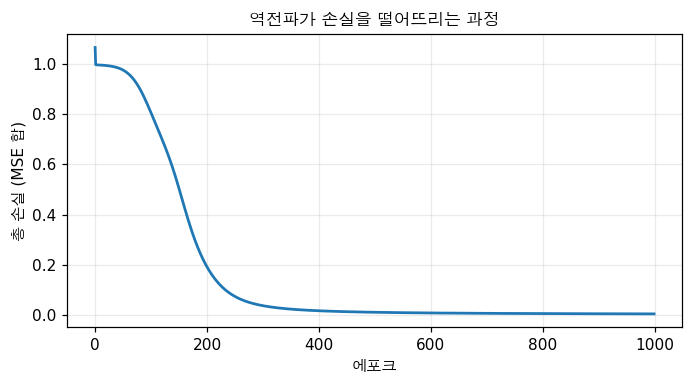

=> 그래프 앞쪽이 거의 평평하다가 갑자기 떨어집니다.
   100~200 에포크 구간이요. 손실 0.806 -> 0.190.

   왜 처음에 평평할까요? 02단원 8절에서 본 그 상태이기 때문입니다.
   출력이 전부 0.5 근처라 네 입력에 거의 같은 답을 하고 있거든요.
   대칭이 깨지기 전까지는 기울기가 서로 상쇄됩니다.
   대칭이 깨지는 순간부터 빠르게 내려갑니다.


In [6]:
XOR데이터 = [([0.0, 0.0], 0.0), ([0.0, 1.0], 1.0), ([1.0, 0.0], 1.0), ([1.0, 1.0], 0.0)]

random.seed(42)
망 = 신경망([2, 4, 1])
학습률 = 1.0
손실기록 = []

for 에포크 in range(1000):
    총손실 = 값(0.0)
    for 입력, 정답2 in XOR데이터:
        총손실 = 총손실 + MSE손실(망([값(v) for v in 입력]), 정답2)

    망.기울기초기화()
    총손실.backward()
    for p in 망.파라미터():
        p.data -= 학습률 * p.grad

    손실기록.append(총손실.data)

print(f"2-4-1 신경망, 파라미터 {len(망.파라미터())}개, 학습률 {학습률}\n")
print(f"{'에포크':>8}{'총 손실':>14}")
print("-" * 24)
for e in (0, 100, 200, 300, 500, 999):
    print(f"{e:>8}{손실기록[e]:>14.6f}")

print(f"\n📗 원문 출력과 대조: Epoch 0 -> 1.067385,  Epoch 900 -> 0.003385")
print(f"   이 노트북:        Epoch 0 -> {손실기록[0]:.6f},  Epoch 900 -> {손실기록[900]:.6f}")

print(f"\n학습된 신경망의 XOR 출력\n")
print(f"{'입력':<14}{'출력':>12}{'반올림':>9}{'정답':>7}")
print("-" * 44)
전부맞음 = True
for 입력, 정답2 in XOR데이터:
    v = 망([값(i) for i in 입력]).data
    예측 = 1 if v >= 0.5 else 0
    전부맞음 &= 예측 == int(정답2)
    print(f"{str(입력):<14}{v:>12.4f}{예측:>9}{int(정답2):>7}  {'✔' if 예측 == 정답2 else '✘'}")

print(f"\nXOR 해결: {전부맞음}")

plt.figure(figsize=(6.4, 3.6))
plt.plot(손실기록, lw=1.8, color="#1f77b4")
plt.xlabel("에포크")
plt.ylabel("총 손실 (MSE 합)")
plt.title("역전파가 손실을 떨어뜨리는 과정", fontsize=11)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"=> 그래프 앞쪽이 거의 평평하다가 갑자기 떨어집니다.")
print(f"   100~200 에포크 구간이요. 손실 {손실기록[100]:.3f} -> {손실기록[200]:.3f}.")
print(f"\n   왜 처음에 평평할까요? 02단원 8절에서 본 그 상태이기 때문입니다.")
print(f"   출력이 전부 0.5 근처라 네 입력에 거의 같은 답을 하고 있거든요.")
print(f"   대칭이 깨지기 전까지는 기울기가 서로 상쇄됩니다.")
print(f"   대칭이 깨지는 순간부터 빠르게 내려갑니다.")

> **👀 주목할 곳** — 손실 그래프의 **앞쪽 평평한 구간**과 그 뒤 급락.
>
> **✅ 알게 된 사실** — 역전파가 가중치를 스스로 찾습니다. 02단원에서 손으로 넣던 것을요. 📗 원문 숫자와도 일치합니다.
앞쪽이 평평한 건 **02단원 8절의 그 상태** 때문입니다. 네 입력에 거의 같은 답을 하고 있어서
기울기가 서로 상쇄되거든요. **대칭이 깨지는 순간부터** 급격히 내려갑니다.

> **🧩 이 절의 결론**
>
> 역전파 + 경사 하강법으로 XOR 이 학습됩니다. 손실 1.07 → 0.003.
> **가중치를 하나도 안 알려 줬는데** 찾아냅니다.
> 앞쪽이 평평한 건 대칭이 안 깨진 구간이고요.
>
> **➡️ 다음**
>
> XOR 은 점이 네 개뿐입니다. 02단원 7절의 **원 분류**를 가져와 봅니다. 8절입니다.

---

## 8. 원 분류 학습시키기

<sub>📗 원문 "Step 7: Circle Classification"</sub>

02단원 8절에서 **무작위 가중치로는 입력을 보지도 않던** 그 문제입니다.
이번엔 학습시킵니다.

### 📗 한 가지 바뀌는 것: 온라인 SGD

> 📗 원문: 여기서는 **온라인 SGD** 를 씁니다.
> 전체 배치를 모아서가 아니라 **샘플마다** 가중치를 갱신해요.
> **대칭이 더 빨리 깨지고**, 전체 손실 지형에서 시그모이드가 포화되는 걸 피합니다.
> 그리고 에포크마다 **데이터를 섞어서** 순서를 외우지 못하게 합니다.

7절의 XOR 은 네 샘플 손실을 **다 더한 뒤** 한 번 갱신했습니다(배치).
여기서는 **샘플 하나 보고 바로 갱신**합니다.
7절 그래프의 평평한 구간이 바로 그 '대칭' 문제였죠.

> **실험 8** · 원 분류를 학습시키기
>
> **🎯 배울 것** — 02단원에서 **손도 못 대던 문제**를 역전파가 푸는지 봅니다.
>
> **🔬 하는 일** — 📗 원문대로 2-8-1 신경망을 온라인 SGD 로 2000 에포크 학습시키고, 학습된 결정 경계를 그려 봅니다.

In [7]:
# 📗 원문의 데이터 생성 (반지름 1, 범위 ±1.5)
def 원데이터만들기(n=80):
    data = []
    for _ in range(n):
        x1 = random.uniform(-1.5, 1.5)
        x2 = random.uniform(-1.5, 1.5)
        정답2 = 1.0 if x1 * x1 + x2 * x2 < 1.0 else 0.0
        data.append(([x1, x2], 정답2))
    return data


random.seed(7)
원데이터 = 원데이터만들기(80)
원망 = 신경망([2, 8, 1])
학습률2 = 0.5
안쪽 = int(sum(t for _, t in 원데이터))

print(f"데이터 {len(원데이터)}점 (안쪽 {안쪽}개, 바깥 {len(원데이터)-안쪽}개)")
print(f"신경망 2-8-1, 파라미터 {len(원망.파라미터())}개, 온라인 SGD, 학습률 {학습률2}\n")


def 정확도재기(net, data):
    맞음 = sum((1.0 if net([값(v) for v in x]).data > 0.5 else 0.0) == t for x, t in data)
    return 맞음 / len(data)


print(f"{'에포크':>8}{'총 손실':>12}{'정확도':>10}")
print("-" * 32)
정확도기록 = []
for 에포크 in range(2000):
    random.shuffle(원데이터)
    총 = 0.0
    for 입력, 정답2 in 원데이터:
        손실하나 = MSE손실(원망([값(v) for v in 입력]), 정답2)
        원망.기울기초기화()
        손실하나.backward()
        for p in 원망.파라미터():
            p.data -= 학습률2 * p.grad
        총 += 손실하나.data
    if 에포크 % 400 == 0 or 에포크 == 1999:
        정 = 정확도재기(원망, 원데이터)
        정확도기록.append((에포크, 총, 정))
        print(f"{에포크:>8}{총:>12.4f}{정:>10.1%}")

print(f"\n📗 원문 출력과 대조: Epoch 0 -> 70.0%,  Epoch 200 이후 -> 100.0%")

데이터 80점 (안쪽 24개, 바깥 56개)
신경망 2-8-1, 파라미터 33개, 온라인 SGD, 학습률 0.5

     에포크        총 손실       정확도
--------------------------------
       0     17.1256     70.0%
     400      0.1224    100.0%
     800      0.0435    100.0%
    1200      0.0236    100.0%
    1600      0.0155    100.0%
    1999      0.0115    100.0%

📗 원문 출력과 대조: Epoch 0 -> 70.0%,  Epoch 200 이후 -> 100.0%


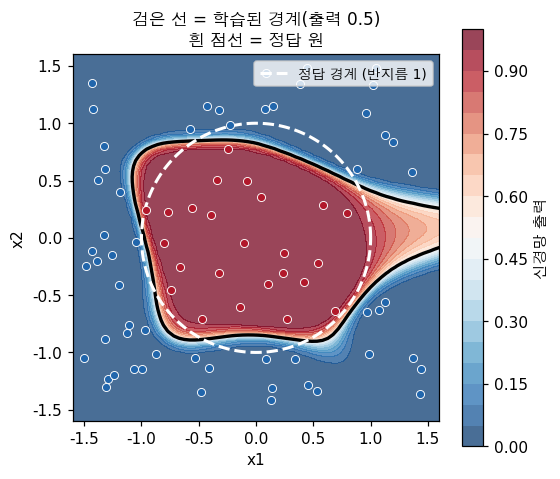

=> 검은 선이 흰 점선을 꽤 비슷하게 따라갑니다.
   원을 그리라고 알려 준 적이 없습니다. 점 80개만 줬어요.

   📝 02단원 8절과 비교해 보세요.
   거기선 출력 폭이 0.1 뿐이라 색이 균일했을 겁니다. 입력을 안 봤으니까요.
   지금은 가운데가 빨갛고 바깥이 파랗습니다. 입력을 보고 있습니다.

   그리고 경계가 완벽한 원은 아닙니다. 모서리가 조금 각져 있죠.
   은닉 뉴런 8개가 만드는 곡선의 한계입니다. 뉴런을 늘리면 더 둥글어집니다.
   02단원 9절의 보편 근사 정리가 말하는 게 그거고요.


In [8]:
# ✨ 추가 — 학습된 결정 경계를 그려 봅니다
격자수 = 70
xs = np.linspace(-1.6, 1.6, 격자수)
면 = np.zeros((격자수, 격자수))
for i, yy in enumerate(xs):
    for j, xx2 in enumerate(xs):
        면[i, j] = 원망([값(float(xx2)), 값(float(yy))]).data

plt.figure(figsize=(5.2, 4.6))
plt.contourf(xs, xs, 면, levels=20, cmap="RdBu_r", alpha=0.75)
plt.colorbar(label="신경망 출력")
plt.contour(xs, xs, 면, levels=[0.5], colors="k", linewidths=2.2)
각도 = np.linspace(0, 2 * np.pi, 200)
plt.plot(np.cos(각도), np.sin(각도), "w--", lw=2, label="정답 경계 (반지름 1)")
for (a1, a2), t in 원데이터:
    plt.scatter(a1, a2, s=28, c="#b2182b" if t else "#2166ac",
                edgecolors="white", linewidths=0.6, zorder=3)
plt.legend(loc="upper right", fontsize=9)
plt.title("검은 선 = 학습된 경계(출력 0.5)\n흰 점선 = 정답 원", fontsize=11)
plt.xlabel("x1")
plt.ylabel("x2")
plt.gca().set_aspect("equal")
plt.tight_layout()
plt.show()

print(f"=> 검은 선이 흰 점선을 꽤 비슷하게 따라갑니다.")
print(f"   원을 그리라고 알려 준 적이 없습니다. 점 {len(원데이터)}개만 줬어요.")
print(f"\n   📝 02단원 8절과 비교해 보세요.")
print(f"   거기선 출력 폭이 0.1 뿐이라 색이 균일했을 겁니다. 입력을 안 봤으니까요.")
print(f"   지금은 가운데가 빨갛고 바깥이 파랗습니다. 입력을 보고 있습니다.")
print(f"\n   그리고 경계가 완벽한 원은 아닙니다. 모서리가 조금 각져 있죠.")
print(f"   은닉 뉴런 8개가 만드는 곡선의 한계입니다. 뉴런을 늘리면 더 둥글어집니다.")
print(f"   02단원 9절의 보편 근사 정리가 말하는 게 그거고요.")

> **👀 주목할 곳** — 검은 선(학습된 경계)이 흰 점선(정답 원)을 따라가는 것, 그리고 색이 **가운데 빨강 / 바깥 파랑**으로 갈리는 것.
>
> **✅ 알게 된 사실** — 역전파가 **곡선 경계를 스스로 찾아냅니다.** 원을 그리라고 알려 준 적이 없습니다.
02단원 8절에서는 출력 폭이 0.1 뿐이라 색이 균일했을 자리입니다. 지금은 **입력에 따라 출력이 변합니다.**
다만 경계가 완벽한 원은 아니고 조금 각져 있습니다. 은닉 뉴런 8개의 한계예요.

> **🧩 이 절의 결론**
>
> 역전파가 **곡선 결정 경계**를 스스로 찾습니다. 02단원에서 손도 못 대던 문제를요.
> 구조와 손실 함수와 데이터만 주면 **알고리즘이 가중치를 알아냅니다.**
>
> **➡️ 다음**
>
> 여기까지가 좋은 소식입니다. **나쁜 소식**이 하나 있습니다.
> 층을 깊게 쌓으면 이 방법이 **먹히지 않습니다.** 10절입니다.

---

## 9. ⚠️ 소실 기울기 — 0.25ⁿ 은 낙관적인 하한

<sub>📗 원문 "Vanishing Gradients" + ✨ 반증</sub>

📗 원문의 계산입니다.

> 각 층에서 기울기에 **시그모이드 미분이 곱해집니다.**
> 시그모이드 미분은 $a(1-a)$ 인데 **최대가 0.25** 입니다($a = 0.5$ 일 때).
>
> 3층이면 기울기에 **최대** $0.25^3 = 0.0156$ 이 곱해집니다.
> 10층이면 $0.25^{10} = 0.000001$ 이고요.

| 깊이 | 📗 원문의 계산 |
| --- | --- |
| 5층 | $0.25^5 = 0.001$ 배 |
| 10층 | $0.25^{10} = 0.000001$ 배 |

> 📗 원문: 그래서 **깊은 시그모이드 신경망은 학습이 거의 불가능**합니다.
> 앞쪽 층은 **거의 0 에 가까운 기울기**를 받으니까요.

### 🔑 '최대' 라는 말을 눈여겨보세요

$0.25$ 는 **가장 좋을 때**의 값입니다. $a$ 가 0.5 에서 멀어지면 더 작아지죠.
그러니 $0.25^n$ 은 **실제로 일어날 수 있는 가장 덜 나쁜 경우**입니다.

실제로 재 보면 얼마나 나쁠까요?

> **실험 9** · ⚠️ 층별 기울기 크기를 직접 재기
>
> **🎯 배울 것** — 📗 연습문제 5번입니다. 소실 기울기가 **얼마나 심한지** 숫자로 봅니다.
>
> **🔬 하는 일** — 은닉층 5개짜리 신경망을 만들고 층마다 기울기 평균 크기를 잰 뒤, 0.25ⁿ 예측과 비교합니다.

In [9]:
# 📗 연습문제 5번 — 층별 기울기 크기
random.seed(42)
깊은망 = 신경망([2, 4, 4, 4, 4, 4, 1])        # 은닉 5층
MSE손실(깊은망([값(0.5), 값(-0.5)]), 1.0).backward()

print("구조 2-4-4-4-4-4-1 (은닉 5층), 학습 전\n")
print(f"{'층':>4}{'위치':>12}{'파라미터':>9}{'기울기 평균 |g|':>18}{'출력층 대비':>14}")
print("-" * 60)
층별평균 = []
for i, 층하나 in enumerate(깊은망.층들):
    gs = [abs(p.grad) for p in 층하나.파라미터()]
    층별평균.append(statistics.mean(gs))
위치표 = ["첫 은닉"] + [f"은닉 {i}" for i in range(2, 6)] + ["출력"]
끝값 = 층별평균[-1]
for i, (평균, 위치) in enumerate(zip(층별평균, 위치표)):
    print(f"{i:>4}{위치:>12}{len(깊은망.층들[i].파라미터()):>9}"
          f"{평균:>18.3e}{끝값/평균:>13,.0f}배")

실제배율 = 끝값 / 층별평균[0]
예측배율 = 1.0 / (0.25 ** 5)                 # 📗 원문의 0.25^5 을 배수로 뒤집은 값
print(f"\n=> 첫 은닉층이 출력층보다 {실제배율:,.0f}배 작은 기울기를 받습니다.")
print(f"   📗 원문의 0.25^5 예측은 {예측배율:,.0f}배인데, "
      f"실제는 그보다 {실제배율/예측배율:.0f}배 더 심합니다.")

print("\n\n⚠️ 층을 늘려 가며 같은 걸 재 봅니다\n")
print(f"{'은닉 층수':>9}{'첫 층 기울기':>16}{'출력층 대비 (실제)':>20}{'0.25^n 예측':>16}{'실제가 몇 배 더 나쁜가':>22}")
print("-" * 86)
for 은닉층수 in (1, 2, 3, 5, 8):
    random.seed(42)
    n2 = 신경망([2] + [4] * 은닉층수 + [1])
    MSE손실(n2([값(0.5), 값(-0.5)]), 1.0).backward()
    첫 = statistics.mean([abs(p.grad) for p in n2.층들[0].파라미터()])
    끝 = statistics.mean([abs(p.grad) for p in n2.층들[-1].파라미터()])
    실제배 = 끝 / 첫
    예측배 = 1 / 0.25 ** 은닉층수
    print(f"{은닉층수:>9}{첫:>16.3e}{실제배:>19,.0f}배{예측배:>15,.0f}배"
          f"{실제배/예측배:>21.0f}배")

print(f"\n=> ⚠️ 실제가 예측보다 20~30배 더 나쁩니다. 그리고 깊어질수록 격차가 벌어져요.")
print(f"\n   왜냐면 각 층에서 곱해지는 게 시그모이드 미분 하나가 아니기 때문입니다.")
print(f"   기울기는 앞 층으로 넘어갈 때 가중치도 함께 곱해집니다(1절의 dL/da1 = dL/dz2 · W2).")
print(f"   그런데 초기화가 sqrt(2/입력수) 라 입력 4개면 가중치가 ±0.707 범위예요.")
print(f"   평균 크기가 1 보다 작습니다. 그래서 시그모이드 미분과 함께 곱해져 더 줄어듭니다.")
print(f"\n   📝 그러니 0.25^n 은 '이만큼은 줄어든다' 는 하한이지")
print(f"      '이만큼만 줄어든다' 는 상한이 아닙니다. 실제로는 더 나쁩니다.")
print(f"\n   💡 그리고 역전파가 틀린 게 아닙니다. 6절에서 검증했듯 기울기는 정확합니다.")
print(f"      📗 원문 표현대로 '역전파는 완벽히 작동합니다.")
print(f"      문제는 그것이 통과해 지나가는 대상입니다.'")

구조 2-4-4-4-4-4-1 (은닉 5층), 학습 전

   층          위치     파라미터        기울기 평균 |g|        출력층 대비
------------------------------------------------------------
   0        첫 은닉       12         7.343e-06       19,411배
   1        은닉 2       20         3.048e-05        4,677배
   2        은닉 3       20         1.519e-04          938배
   3        은닉 4       20         2.611e-03           55배
   4        은닉 5       20         8.861e-03           16배
   5          출력        5         1.425e-01            1배

=> 첫 은닉층이 출력층보다 19,411배 작은 기울기를 받습니다.
   📗 원문의 0.25^5 예측은 1,024배인데, 실제는 그보다 19배 더 심합니다.


⚠️ 층을 늘려 가며 같은 걸 재 봅니다

    은닉 층수         첫 층 기울기         출력층 대비 (실제)       0.25^n 예측         실제가 몇 배 더 나쁜가
--------------------------------------------------------------------------------------
        1       1.440e-02                 14배              4배                    3배
        2       4.524e-03                 33배             16배                    2배
        3       7.684e-04                249배  

> **👀 주목할 곳** — 두 번째 표의 맨 오른쪽 열. **전부 20배 이상**이고 깊어질수록 커집니다.
>
> **✅ 알게 된 사실** — ⚠️ 📗 원문의 $0.25^n$ 은 **하한**입니다. 실제 감쇠는 그보다 20~30배 더 심합니다.
기울기가 앞 층으로 갈 때 **시그모이드 미분과 가중치가 함께** 곱해지는데,
초기화가 $\sqrt{2/n}$ 이라 가중치 크기가 1 보다 작아서 더 줄어들거든요.
그리고 **역전파는 틀리지 않았습니다.** 6절에서 검증했죠. 문제는 시그모이드입니다.

> **🧩 이 절의 결론**
>
> ⚠️ 소실 기울기는 📗 원문의 $0.25^n$ 계산보다 **20~30배 더 심합니다.**
> 시그모이드 미분뿐 아니라 **가중치도 함께 곱해지기** 때문입니다.
> 역전파 자체는 정확합니다. 문제는 **시그모이드**예요.
>
> **➡️ 다음**
>
> 그럼 시그모이드를 바꾸면 될까요? 📗 연습문제 2번이 그걸 시킵니다.
> ReLU 로 바꾸면 빨라진다는데, 재 보면 조건이 붙습니다. 10절입니다.

---

## 10. ⚠️ ReLU 로 바꾸면 빨라지나

<sub>📗 원문 연습문제 2번 + ✨ 측정</sub>

📗 원문 연습문제 2번입니다.

> `Value` 에 `relu` 메서드를 추가하세요.
> 출력은 $\max(0, x)$, 미분은 $x > 0$ 이면 1, 아니면 0 입니다.
> 은닉층의 시그모이드를 relu 로 바꾸고 XOR 을 다시 학습시키세요.
> **수렴 속도를 비교하면 더 빨라야 합니다.**

왜 빨라질까요? **미분이 0.25 가 아니라 1** 이기 때문입니다.
9절에서 본 감쇠가 안 일어나죠.

$$\text{ReLU}'(x) = \begin{cases} 1 & x > 0 \\ 0 & x \le 0 \end{cases}$$

그런데 **아랫줄을 보세요.** $x \le 0$ 이면 미분이 **0** 입니다.
그 뉴런으로는 기울기가 **전혀 안 흐릅니다.**

정말 더 빨라지는지 재 봅니다.

> **실험 10** · ⚠️ ReLU vs 시그모이드
>
> **🎯 배울 것** — 'ReLU 가 더 빠르다' 가 **그냥 맞는 말인지** 확인합니다.
>
> **🔬 하는 일** — `relu` 를 구현해 은닉층에 끼우고, 학습률과 은닉 뉴런 수를 바꿔 가며 시그모이드와 겨룹니다. 죽은 뉴런도 셉니다.

In [10]:
# 📗 연습문제 2번 — relu 를 Value 에 추가합니다
def relu(self):
    out = 값(max(0.0, self.data), (self,), "relu")

    def _역방향():
        self.grad += (1.0 if self.data > 0 else 0.0) * out.grad
    out._backward = _역방향
    return out


값.relu = relu


class ReLU뉴런(뉴런):
    def __call__(self, x):
        z = sum((w * xi for w, xi in zip(self.가중치, x)), self.편향)
        return z.relu()


def 망만들기(은닉수, 렐루, 시드=42):
    random.seed(시드)
    net = 신경망([2, 은닉수, 1])
    if 렐루:
        for 층하나 in net.층들[:-1]:        # 출력층은 시그모이드로 둡니다
            층하나.뉴런들 = [ReLU뉴런(len(n.가중치)) for n in 층하나.뉴런들]
    return net


def XOR학습(net, 학습률3, 에포크=1000):
    for _ in range(에포크):
        총 = 값(0.0)
        for 입력, 정답2 in XOR데이터:
            총 = 총 + MSE손실(net([값(v) for v in 입력]), 정답2)
        net.기울기초기화()
        총.backward()
        for p in net.파라미터():
            p.data -= 학습률3 * p.grad
    return 총.data


def 죽은뉴런세기(net):
    죽음 = 0
    for 층하나 in net.층들[:-1]:
        for n in 층하나.뉴런들:
            if all(n([값(v) for v in x]).data == 0.0 for x, _ in XOR데이터):
                죽음 += 1
    return 죽음


print("① 학습률을 바꿔 가며 (은닉 뉴런 4개, 1000 에포크)\n")
print(f"{'학습률':>8}{'sigmoid 손실':>16}{'ReLU 손실':>14}{'죽은 ReLU 뉴런':>16}")
print("-" * 56)
for 학습률3 in (0.05, 0.1, 0.3, 1.0):
    s = XOR학습(망만들기(4, False), 학습률3)
    r망 = 망만들기(4, True)
    r = XOR학습(r망, 학습률3)
    print(f"{학습률3:>8}{s:>16.4f}{r:>14.4f}{죽은뉴런세기(r망):>12}/4 개")

print(f"\n=> ⚠️ ReLU 가 전부 0.50 근처에서 멈췄습니다. 학습률을 어떻게 바꿔도요.")
print(f"   📗 연습문제는 '더 빨라야 한다' 고 했는데 반대 결과입니다.")
print(f"   `죽은 ReLU 뉴런` 열을 보세요. 4개 중 2개가 죽었습니다.")
print(f"   네 입력 모두에 0 을 내놓는 뉴런이에요. 기울기가 0 이라 되살아나지 못합니다.")

print("\n\n② 은닉 뉴런을 늘려 보면 (학습률 0.1)\n")
print(f"{'은닉 수':>8}{'sigmoid 손실':>16}{'ReLU 손실':>14}{'죽은 뉴런':>12}{'승자':>8}")
print("-" * 60)
for 은닉수 in (4, 8, 16):
    s = XOR학습(망만들기(은닉수, False), 0.1)
    r망 = 망만들기(은닉수, True)
    r = XOR학습(r망, 0.1)
    print(f"{은닉수:>8}{s:>16.4f}{r:>14.4f}{죽은뉴런세기(r망):>8}/{은닉수} 개"
          f"{'ReLU' if r < s else 'sigmoid':>8}")

print(f"\n=> ⚠️ 뉴런을 8개로 늘리니 ReLU 가 압도합니다. 손실이 0.80 대 0.008 이에요.")
print(f"   100배 차이입니다. 📗 연습문제의 '더 빠르다' 가 여기서는 맞습니다.")
print(f"\n   📝 그래서 정확히 말하면 이렇습니다.")
print(f"      ReLU 는 더 빠릅니다. 단, 죽은 뉴런을 견딜 만큼 층이 넓을 때요.")
print(f"      뉴런 4개에서 2개가 죽으면 남은 2개로는 XOR 을 못 풉니다(01단원 7절).")
print(f"      8개에서 1개가 죽는 건 괜찮고요.")
print(f"\n   💡 이게 04단원(활성화 함수) 의 주제입니다.")
print(f"      ReLU 의 '죽는 뉴런' 문제를 고치려고 Leaky ReLU, ELU, GELU 같은 게 나왔거든요.")

① 학습률을 바꿔 가며 (은닉 뉴런 4개, 1000 에포크)

     학습률      sigmoid 손실       ReLU 손실      죽은 ReLU 뉴런
--------------------------------------------------------
    0.05          0.9765        0.5049           2/4 개
     0.1          0.8019        0.5016           2/4 개
     0.3          0.0353        0.5003           2/4 개
     1.0          0.0029        0.5001           2/4 개

=> ⚠️ ReLU 가 전부 0.50 근처에서 멈췄습니다. 학습률을 어떻게 바꿔도요.
   📗 연습문제는 '더 빨라야 한다' 고 했는데 반대 결과입니다.
   `죽은 ReLU 뉴런` 열을 보세요. 4개 중 2개가 죽었습니다.
   네 입력 모두에 0 을 내놓는 뉴런이에요. 기울기가 0 이라 되살아나지 못합니다.


② 은닉 뉴런을 늘려 보면 (학습률 0.1)

    은닉 수      sigmoid 손실       ReLU 손실       죽은 뉴런      승자
------------------------------------------------------------
       4          0.8019        0.5016       2/4 개    ReLU
       8          0.6683        0.0084       1/8 개    ReLU
      16          0.5758        0.0046       5/16 개    ReLU

=> ⚠️ 뉴런을 8개로 늘리니 ReLU 가 압도합니다. 손실이 0.80 대 0.008 이에요.
   100배 차이입니다. 📗 연습문제의 '더 빠르다' 가 여기서는 맞습니다.

   📝 그래서 정확히 말하면 이렇습니다.
      R

> **👀 주목할 곳** — ① 의 `죽은 ReLU 뉴런` 열(4개 중 2개)과 ② 에서 뉴런을 8개로 늘렸을 때의 역전.
>
> **✅ 알게 된 사실** — ⚠️ 📗 연습문제는 'ReLU 가 더 빨라야 한다' 고 하는데, **뉴런 4개에서는 전부 0.5 에서 멈춥니다.**
4개 중 2개가 죽어서예요. ReLU 는 음수 구간 미분이 0 이라 **한 번 죽으면 못 돌아옵니다.**
그런데 8개로 늘리면 **시그모이드를 100배 차이로 이깁니다**(0.80 대 0.008).
정확히는 **'ReLU 는 더 빠르다, 단 죽은 뉴런을 견딜 만큼 넓을 때'** 입니다.

> **🧩 이 절의 결론**
>
> ⚠️ ReLU 는 시그모이드보다 빠릅니다. **조건이 붙습니다** — 층이 충분히 넓어야 해요.
> 미분이 1 이라 9절의 감쇠를 피하지만, 음수 구간 미분이 0 이라 **뉴런이 죽습니다.**
> 뉴런 4개에서 2개가 죽으면 끝이고, 8개에서 1개가 죽는 건 괜찮습니다.
>
> **➡️ 다음**
>
> 11절에서 전체를 정리합니다.
> 그리고 여기서 드러난 활성화 함수 문제가 **04단원**의 주제입니다.

---

## 11. 정리

### ⚠️ 이 노트북에서 원문과 달랐던 것

| 📗 원문 | 측정 결과 | 절 |
| --- | --- | --- |
| 소실 기울기는 "5층이면 $0.25^5$ = 0.001배, 10층이면 $0.25^{10}$" | ⚠️ **실제는 20~30배 더 심합니다.** 은닉 5층에서 첫 층이 출력층보다 19,411배 작은 기울기를 받습니다($0.25^5$ 예측은 1,024배). 기울기에 시그모이드 미분뿐 아니라 **가중치도 함께** 곱해지기 때문입니다 | 9 |
| 연습문제 2번 — ReLU 로 바꾸면 "**더 빨라야 합니다**" | ⚠️ **은닉 뉴런 4개에서는 반대입니다.** 4개 중 2개가 죽어 손실 0.50 에서 멈춥니다. 학습률을 20배 바꿔도 같고요. 8개로 늘리면 그제야 시그모이드를 100배 차이로 이깁니다(0.80 대 0.008) | 10 |

### ✨ 원문에 없는데 넣은 것

| 내용 | 왜 | 절 |
| --- | --- | --- |
| **기울기 검증** (수치미분 대조) | 역전파는 **틀려도 에러가 안 납니다.** 실무에서 반드시 하는 검사예요. 측정 결과 상대 오차 7e-09 로 통과 | 6 |
| `+=` 를 `=` 로 바꾸면 생기는 일 | $x \cdot x$ 의 기울기가 6 이 아니라 3 이 됩니다 | 4 |
| 학습된 결정 경계 그림 | 02단원 8절의 '균일한 색' 과 대조하려고 | 8 |

### ✅ 측정으로 확인된 원문의 주장

| 📗 원문의 주장 | 결과 | 절 |
| --- | --- | --- |
| XOR 학습: 손실 1.067385 → 0.003385 | ✅ 소수점까지 일치 | 7 |
| 원 분류: 70% → 100% | ✅ 재현 | 8 |
| 역전파는 모든 기울기를 한 번에 구한다 | ✅ 수치미분과 10자리까지 일치하면서 역방향 1번 | 6 |
| 깊은 시그모이드 신경망은 학습이 거의 불가능하다 | ✅ 은닉 8층에서 첫 층 기울기가 6e-08 | 9 |

### 🔑 한 줄로 꿰면

> **모든 숫자에 '내가 어떻게 만들어졌나' 를 붙여 두면,
> 손실에서 거꾸로 한 번 훑는 것만으로 모든 기울기를 구할 수 있습니다.**

그게 `Value._자식` 이 하는 일이고, `backward()` 가 하는 일입니다.
PyTorch 의 autograd 도 **정확히 같은 구조**고요.

### Phase 3 의 01~03단원이 한 묶음입니다

| 단원 | 질문 | 답 |
| --- | --- | --- |
| **01** | 뉴런 하나로 뭘 할 수 있나 | 선 하나. 2입력 함수 16개 중 14개 |
| **02** | 쌓으면 어떻게 되나 | 곡선이 생긴다. 다만 **가중치를 손으로** 넣어야 했다 |
| **03** | 그 가중치를 어떻게 찾나 | **역전파.** 다만 깊어지면 기울기가 사라진다 |

그리고 03단원이 새 숙제를 남깁니다.

| 숙제 | 어디서 |
| --- | --- |
| 시그모이드 말고 뭘 쓰나 (ReLU 의 죽는 뉴런 문제 포함) | **04단원** (활성화 함수) |
| MSE 말고 뭘 쓰나 | **05단원** (손실 함수) |
| `p.data -= lr * p.grad` 보다 나은 갱신 방법 | **06단원** (옵티마이저) |
| 가중치를 어떻게 초기화하나 (9절에서 본 그 $\sqrt{2/n}$) | **08단원** (가중치 초기화) |

---

## 🔧 PyTorch 로는

<sub>📗 원문 "Use It"</sub>

```python
import torch
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(2, 4), nn.Sigmoid(),
    nn.Linear(4, 1), nn.Sigmoid(),
)
optimizer = torch.optim.SGD(model.parameters(), lr=1.0)
criterion = nn.MSELoss()

X = torch.tensor([[0,0],[0,1],[1,0],[1,1]], dtype=torch.float32)
y = torch.tensor([[0],[1],[1],[0]], dtype=torch.float32)

for epoch in range(1000):
    pred = model(X)
    loss = criterion(pred, y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
```

### 이 노트북과 하나씩 대응됩니다

| 이 노트북 | PyTorch | 하는 일 |
| --- | --- | --- |
| `망.기울기초기화()` | `optimizer.zero_grad()` | 지난 기울기 지우기 |
| `총손실.backward()` | `loss.backward()` | **역전파** |
| `p.data -= 학습률 * p.grad` | `optimizer.step()` | 가중치 갱신 |
| `값._자식` | autograd 의 `grad_fn` | 그래프 연결 정보 |
| `값.grad` | `tensor.grad` | 누적된 기울기 |

> 📗 원문: **같은 알고리즘, 산업용 구현**입니다.
> PyTorch 는 GPU 가속, 혼합 정밀도, 기울기 체크포인팅, 수백 가지 층을 다룹니다.
> 하지만 **역방향 패스는 같은 계산 그래프에 같은 연쇄법칙을 적용한 것**입니다.

### 🔑 학습과 추론의 차이

> 📗 원문: **학습**은 순전파 → 역전파 → 가중치 갱신을 돕니다.
> **추론**은 순전파만 합니다. 기울기도 없고 갱신도 없어요.
>
> 이 구분이 중요한 건 **운영 환경에서 벌어지는 게 추론**이기 때문입니다.
> Claude 나 GPT 같은 API 를 부르면 여러분은 **추론을 돌리는 겁니다.**
> 프롬프트가 신경망을 앞으로 흘러가고 토큰이 반대쪽으로 나옵니다. **가중치는 안 바뀝니다.**
>
> 역전파를 이해하는 게 중요한 이유는
> **그 신경망의 모든 가중치를 역전파가 빚어냈기 때문**입니다.

---

## 🚀 Ship It — `prompt-gradient-debugger.md`

<sub>📗 원문 저장소의 `03-backpropagation/outputs/prompt-gradient-debugger.md` (85줄)</sub>

> 📗 원문: 어떤 신경망에서든 **기울기 문제(소실·폭주·NaN)를 진단**하는 재사용 프롬프트입니다.

### 진단 순서

| 순서 | 증상 | 의심할 것 | 이 단원의 근거 |
| --- | --- | --- | --- |
| 1 | 손실이 `NaN` | 학습률이 너무 큼, `log(0)`, 0 으로 나눔 | — |
| 2 | 손실이 **안 움직임** | 기울기 소실, 죽은 뉴런 | 9·10절 |
| 3 | 손실이 **발산** | 기울기 폭주, 학습률 과다 | 📗 연습문제 4번(클리핑) |
| 4 | 앞쪽 층만 학습이 안 됨 | **기울기 소실** | 9절 |
| 5 | 기울기가 아예 **0** | ReLU 가 죽음, 연결 끊김 | 10절 |

### ✨ 추가 — 측정 뒤에 제가 덧붙인 세 가지

```markdown
## 기울기를 손으로 짰다면 (6절)

학습을 돌리기 전에 **반드시 기울기 검증**을 하세요.
수치미분 (L(w+h) - L(w-h)) / 2h 와 비교합니다.

- 상대 오차 1e-5 미만 -> 통과
- 1e-2 쯤 -> 역방향 함수에 버그
측정에서 올바른 구현은 7e-09 가 나왔습니다.

역전파는 틀려도 에러가 안 납니다. 학습이 조금 덜 될 뿐이에요.
그래서 이 검사를 건너뛰면 영영 모릅니다.

## 소실 기울기를 추정할 때 (⚠️ 9절)

0.25^n 으로 어림하지 마세요. **그건 하한입니다.**
측정에서 은닉 5층의 실제 감쇠는 19,411배로,
0.25^5 가 예측한 1,024배보다 19배 심했습니다.

기울기에는 시그모이드 미분뿐 아니라 **가중치도 곱해집니다.**
초기화 규모가 1 보다 작으면 그만큼 더 줄어듭니다.
추정하지 말고 층별로 직접 재세요 (9절 코드 그대로).

## ReLU 로 바꾸기 전에 (⚠️ 10절)

"ReLU 가 더 빠르다" 를 조건 없이 믿지 마세요.
측정에서 은닉 뉴런 4개짜리는 2개가 죽어 손실 0.50 에서 멈췄고,
학습률을 20배 범위로 바꿔도 똑같았습니다.

바꾼 뒤에는 **죽은 뉴런 수를 반드시 세세요.**
모든 입력에 0 을 내놓는 뉴런이 몇 개인지요.
층이 좁으면 ReLU 가 오히려 손해입니다.
```

---

## 📚 용어 정리

<sub>📗 원문 "Key Terms" — 설명은 쉬운 말로 다시 썼습니다</sub>

| 용어 | 흔히 하는 말 | 진짜 무슨 뜻인가 |
| --- | --- | --- |
| **역전파** | "신경망이 학습한다" | 계산 그래프를 거꾸로 훑으며 **모든 가중치의 $\partial L/\partial w$ 를** 연쇄법칙으로 구하는 알고리즘 |
| **계산 그래프** | "신경망 구조" | 노드가 연산이고 간선이 **앞으로는 값, 뒤로는 기울기**를 나르는 방향 그래프 |
| **연쇄법칙** | "미분을 곱한다" | $y = f(g(x))$ 면 $\frac{dy}{dx} = f'(g(x)) \cdot g'(x)$. 역전파의 수학적 토대 |
| **기울기** | "가장 가파른 방향" | 손실을 그 파라미터로 미분한 것. **어느 쪽으로 바꿔야 손실이 주는지** 알려 줍니다 |
| **소실 기울기** | "깊으면 학습이 안 된다" | 포화하는 활성화를 거치며 기울기가 **지수적으로 줄어드는** 현상. ⚠️ $0.25^n$ 보다 더 심합니다 |
| **순전파** | "모델 돌리기" | 입력에서 출력까지 계산하며 **중간값을 저장**하는 것 (역전파가 그 값들을 씁니다) |
| **역방향 패스** | "기울기 계산" | 그래프를 거꾸로 훑으며 노드마다 기울기를 **누적**하는 것 |
| **학습률** | "얼마나 빨리 배우나" | 갱신 보폭. $w_{\text{new}} = w_{\text{old}} - \text{lr} \cdot \text{기울기}$ |
| **위상 정렬** | "올바른 순서" | 각 노드가 **자기가 의존하는 노드 뒤에** 오는 순서. 기울기가 다 모인 뒤 전파되게 합니다 |
| **autograd** | "자동 미분" | 순전파 중에 그래프를 만들고 **자동으로 기울기를 구하는** 시스템. PyTorch 엔진이 하는 일 |
| **기울기 검증** | — | ✨ 자동 기울기를 **수치미분과 대조**해 구현이 맞는지 확인하는 것 |
| **죽은 ReLU** | "뉴런이 죽었다" | ⚠️ 모든 입력에 0 을 내놓는 ReLU 뉴런. 미분도 0 이라 **되살아나지 못합니다** |

---

## 📖 더 읽을 것

<sub>📗 원문 "Further Reading"</sub>

- **Rumelhart, Hinton & Williams, "Learning representations by back-propagating errors" (1986)**
  — 역전파를 주류로 만들고 다층 신경망 학습을 열어젖힌 논문
- **3Blue1Brown, "Neural Networks" 시리즈**
  (<https://www.youtube.com/playlist?list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi>)
  — 역전파와 기울기 흐름을 **시각적으로 가장 잘** 설명합니다
- **Andrej Karpathy, "The spelled-out intro to neural networks and backpropagation"**
  — 이 단원에서 만든 `Value` 엔진과 거의 같은 걸 처음부터 만듭니다. `micrograd` 로도 유명하죠

---

## ✅ 이해 확인 퀴즈

<sub>📗 원문 저장소의 `03-backpropagation/quiz.json` + ✨ 측정 결과를 묻는 문항</sub>

**1. 가중치가 100만 개입니다. 역전파가 기울기를 다 구하는 데 필요한 역방향 패스는?**
1. 100만 번
2. 200만 번
3. **1번**
4. 층 수만큼

**2. 역방향 함수에서 `self.grad += ...` 를 `self.grad = ...` 로 바꾸면?**
1. 아무 차이 없습니다
2. **한 값이 여러 번 쓰인 경우 기울기가 틀립니다**
3. 에러가 납니다
4. 학습이 더 빨라집니다

**3. ✨ 직접 짠 역전파가 맞는지 확인하는 방법은?**
1. 손실이 내려가면 맞는 겁니다
2. **수치미분과 대조합니다**
3. PyTorch 와 속도를 비교합니다
4. 확인할 방법이 없습니다

**4. ⚠️ 은닉 5층 시그모이드 신경망에서 첫 층의 기울기는 출력층 대비 얼마나 작을까요?**
1. $0.25^5$ ≈ 1,024배
2. 5배
3. **약 19,000배 — $0.25^5$ 예측보다 훨씬 심합니다**
4. 차이 없습니다

**5. ⚠️ 은닉 뉴런 4개짜리 XOR 신경망을 ReLU 로 바꾸면?**
1. 더 빨리 수렴합니다
2. **뉴런이 죽어서 손실 0.5 에서 멈춥니다**
3. 똑같습니다
4. 발산합니다

In [11]:
문항들 = [
    ("역방향 패스 횟수", 3,
     "역전파의 핵심이 이겁니다. 순전파 1번으로 그래프와 중간값을 쌓아 두고, "
     "역방향 1번으로 모든 기울기를 구합니다. 수치미분이라면 가중치 하나당 "
     "순전파 2번이라 200만 번이 필요하고요. 격차가 파라미터 수에 비례합니다.",
     "2절 (비용 비교) · 5절 (backward 구현)"),
    ("`+=` 를 `=` 로 바꾸면", 2,
     "한 Value 가 여러 연산에 쓰이면 기울기는 모든 경로의 합입니다. "
     "측정에서 x * x 의 기울기가 += 로는 6(= 3+3), = 로는 3 이 나옵니다. "
     "에러가 안 나고 조용히 틀리는 게 이 버그의 고약한 점입니다.",
     "4절 (y = x * x 로 확인)"),
    ("역전파 구현 검증", 2,
     "손실이 내려가도 기울기가 틀릴 수 있습니다. 조금 덜 학습될 뿐이거든요. "
     "유일한 방법은 (L(w+h) - L(w-h)) / 2h 와 대조하는 겁니다. "
     "측정에서 올바른 구현은 상대 오차 7e-09 가 나왔고, 실무 기준은 1e-5 미만입니다.",
     "6절 (기울기 검증)"),
    ("은닉 5층의 기울기 감쇠", 3,
     "측정에서 출력층 1.425e-01, 첫 은닉층 7.343e-06 으로 19,411배 차이였습니다. "
     "0.25^5 가 예측하는 1,024배보다 19배 심하죠. "
     "기울기에 시그모이드 미분뿐 아니라 가중치도 곱해지는데, "
     "초기화가 sqrt(2/4) = 0.707 이라 가중치 크기가 1 보다 작기 때문입니다.",
     "9절 (층별 기울기 측정)"),
    ("뉴런 4개에서 ReLU 로 바꾸면", 2,
     "측정에서 학습률 0.05~1.0 어디서도 손실이 0.50 아래로 안 내려갔고, "
     "4개 중 2개가 죽은 뉴런이었습니다. ReLU 는 음수 구간 미분이 0 이라 "
     "한 번 죽으면 되살아나지 못합니다. 다만 8개로 늘리면 "
     "시그모이드를 0.80 대 0.008 로 이깁니다.",
     "10절 (ReLU vs 시그모이드 측정)"),
]

print("=" * 80)
for 번호, (제목, 정답3, 해설, 어디) in enumerate(문항들, 1):
    print(f"{번호}. {제목}")
    print(f"   정답: {정답3}번")
    print(f"   해설: {해설}")
    print(f"   이 노트북: {어디}")
    print("-" * 80)

print("\n채점 기준")
print("   5개 다 맞음 -> 04단원(활성화 함수)으로 넘어가세요")
print("   3~4개 맞음  -> 틀린 문항의 '이 노트북' 절만 다시 읽으세요")
print("   2개 이하    -> 4절(역방향 함수)과 5절(backward)을 먼저 보세요")

print("\n\nPhase 3 의 01~03단원")
print("   01단원  퍼셉트론      — 뉴런 하나는 선 하나다")
print("   02단원  다층 신경망    — 쌓으면 곡선이 된다 (가중치는 손으로)")
print("   03단원  역전파        — 그 가중치를 찾는 법              <- 지금 여기")
print("\n   세 단원이 하나의 이야기였습니다.")
print("   01: 하나로는 안 된다 -> 02: 쌓으면 된다 -> 03: 쌓은 걸 가르치는 법")
print("\n   그리고 03단원이 새 문제를 드러냈습니다.")
print("   시그모이드는 깊어지면 기울기를 죽이고, ReLU 는 뉴런을 죽입니다.")
print("   그 둘 사이에서 뭘 쓸지가 04단원(활성화 함수) 입니다.")

1. 역방향 패스 횟수
   정답: 3번
   해설: 역전파의 핵심이 이겁니다. 순전파 1번으로 그래프와 중간값을 쌓아 두고, 역방향 1번으로 모든 기울기를 구합니다. 수치미분이라면 가중치 하나당 순전파 2번이라 200만 번이 필요하고요. 격차가 파라미터 수에 비례합니다.
   이 노트북: 2절 (비용 비교) · 5절 (backward 구현)
--------------------------------------------------------------------------------
2. `+=` 를 `=` 로 바꾸면
   정답: 2번
   해설: 한 Value 가 여러 연산에 쓰이면 기울기는 모든 경로의 합입니다. 측정에서 x * x 의 기울기가 += 로는 6(= 3+3), = 로는 3 이 나옵니다. 에러가 안 나고 조용히 틀리는 게 이 버그의 고약한 점입니다.
   이 노트북: 4절 (y = x * x 로 확인)
--------------------------------------------------------------------------------
3. 역전파 구현 검증
   정답: 2번
   해설: 손실이 내려가도 기울기가 틀릴 수 있습니다. 조금 덜 학습될 뿐이거든요. 유일한 방법은 (L(w+h) - L(w-h)) / 2h 와 대조하는 겁니다. 측정에서 올바른 구현은 상대 오차 7e-09 가 나왔고, 실무 기준은 1e-5 미만입니다.
   이 노트북: 6절 (기울기 검증)
--------------------------------------------------------------------------------
4. 은닉 5층의 기울기 감쇠
   정답: 3번
   해설: 측정에서 출력층 1.425e-01, 첫 은닉층 7.343e-06 으로 19,411배 차이였습니다. 0.25^5 가 예측하는 1,024배보다 19배 심하죠. 기울기에 시그모이드 미분뿐 아니라 가중치도 곱해지는데, 초기화가 sqrt(2/4) = 0.707 이라 가중치 크기가 1